# Part 1, step 1: build the satellite patch dataset

This notebook builds the image dataset for the deforestation CNN. For four study countries it:

1. builds cloud-free Sentinel-2 composites for a **before** year (2018) and an **after** year (2023),
2. uses Hansen Global Forest Change to find places that lost forest between them (2019 to 2022), and places that stayed forest,
3. labels 64 × 64 pixel patches (640 m × 640 m) as `lost` (1) or `stable` (0), balanced between the two classes,
4. downloads the patches as NumPy arrays, plus an index CSV with each patch's location and label.

All heavy processing runs on Google Earth Engine's servers. Run it in Google Colab, or locally in VS Code.

**Before you run it:** you need a Google Earth Engine account registered for noncommercial use and a Google Cloud project ID.

**Why Sentinel-2 Level-1C (top of atmosphere):** the surface-reflectance product only covers the whole tropics from late 2018, so 2018 would have gaps. Using Level-1C for both years keeps the before and after images consistent.

## 1. Settings

In [8]:
# Change these to match your setup
EE_PROJECT = "earth-01-final"   # your Google Cloud project registered for Earth Engine

COUNTRIES = ["Brazil", "Indonesia", "Democratic Republic of the Congo", "India"]

BEFORE_YEAR = 2018            # 'before' image year
AFTER_YEAR = 2023             # 'after' image year
# Loss counted for the 'lost' label: 2019 to 2022. Loss during 2023 itself is not counted,
# because a full-year 2023 image may not show clearing that happened late in the year.
PATCHES_PER_CLASS = 1000      # per country and class, so 2,000 patches per country
# Candidates drawn per patch needed. 'Lost' candidates fail the label rules far more often
# (test run: about 1 in 5 passed, against about 2 in 3 for 'stable'), so more are drawn.
STABLE_CANDIDATE_FACTOR = 1.5
LOST_CANDIDATE_FACTOR = 5
PATCH_PX = 64                 # patch size in pixels
PIXEL_M = 10                  # ground size of one pixel in metres (Sentinel-2 resolution)

# Label rules
TREECOVER_MIN = 30            # % canopy in 2000 for a pixel to count as forest
LOST_MIN_FRACTION = 0.10      # 'lost' patch: at least 10% of its area lost forest in 2019-2022
LOST_BEFORE_MAX = 0.05        #   ...and under 5% of its area lost earlier (2001-2018)
STABLE_MIN_TREECOVER = 50     # 'stable' patch: mean canopy in 2000 at least 50%
STABLE_MAX_LOSS = 0.01        #   ...and under 1% of its area lost at any time 2001-2023
MAX_NODATA_FRACTION = 0.05    # drop patches with more than 5% cloud-masked pixels

BANDS = ["B2", "B3", "B4", "B8", "B11", "B12"]   # blue, green, red, near infrared, two shortwave infrared
CLOUD_SCORE_MIN = 0.60        # Cloud Score+ threshold, higher keeps only clearer pixels

SEED = 42

# Test run: one country and 50 patches per class, to check the pipeline and measure EECU use.
# Set to False for the full run.
TEST_RUN = False
if TEST_RUN:
    COUNTRIES = ["Indonesia"]
    PATCHES_PER_CLASS = 50

# Output folder. In Colab, mount Google Drive first and point this at a Drive folder,
# for example "/content/drive/MyDrive/EARTH_01/part1_patches".
OUT_DIR = "../data/raw/part1_patches"
INDEX_CSV = "../data/cleaned/part1_patch_index.csv"

assert BEFORE_YEAR < AFTER_YEAR - 1, "need at least one full year between the two images"
assert 2001 <= BEFORE_YEAR and AFTER_YEAR <= 2023, "Hansen v1.11 covers loss in 2001-2023"

## 2. Connect to Earth Engine

In [9]:
import os
import time
from concurrent.futures import ThreadPoolExecutor, as_completed

import ee
import numpy as np
import pandas as pd
from numpy.lib import recfunctions as rfn
from pyproj import Transformer
from tqdm.auto import tqdm

ee.Authenticate()   # opens a browser sign-in the first time
ee.Initialize(project=EE_PROJECT, opt_url="https://earthengine-highvolume.googleapis.com")
# Make any single request give up after 3 minutes instead of waiting forever
ee.data.setDeadline(180_000)

os.makedirs(OUT_DIR, exist_ok=True)
os.makedirs(os.path.dirname(INDEX_CSV), exist_ok=True)

## 3. Data sources

- **Country outlines:** FAO GAUL 2015. These are only used to choose where to sample; the website maps use Natural Earth's India point-of-view borders.
- **Forest labels:** Hansen Global Forest Change v1.11 (loss up to 2023). A patch counts as `lost` if it lost forest in 2019 to 2022, between the two images. Loss during 2023 is left out of that label because a full-year 2023 image may not show it yet.
- **Imagery:** Sentinel-2 Level-1C, cloud-masked with Cloud Score+.

In [10]:
countries_fc = ee.FeatureCollection("FAO/GAUL/2015/level0")
hansen = ee.Image("UMD/hansen/global_forest_change_2023_v1_11")

# Earth Engine stores 'no loss' and 'no tree cover' as blank (masked) pixels, not 0.
# unmask(0) turns them into real zeros so the fractions below count every pixel.
treecover = hansen.select("treecover2000").unmask(0)
lossyear = hansen.select("lossyear").unmask(0)      # 0 = no loss, 1-23 = year of loss (2001-2023)
land = hansen.select("datamask").eq(1)              # 1 = land, 2 = water, 0 = no data
forest2000 = treecover.gte(TREECOVER_MIN).And(land)

y0 = BEFORE_YEAR - 2000 + 1                    # first loss year counted, 19 for 2019
y1 = AFTER_YEAR - 2000 - 1                     # last loss year counted, 22 for 2022

lost_window = forest2000.And(lossyear.gte(y0)).And(lossyear.lte(y1))
lost_before = forest2000.And(lossyear.gt(0)).And(lossyear.lt(y0))
lost_any = lossyear.gt(0)
stable_forest = forest2000.And(lost_any.Not())

# One class band for picking candidate points: 1 = lost in the window, 0 = never-lost forest
pixel_class = (ee.Image(-1)
               .where(stable_forest, 0)
               .where(lost_window, 1)
               .updateMask(lost_window.Or(stable_forest))
               .rename("cls")
               .toInt8())

def country_geom(name):
    return countries_fc.filter(ee.Filter.eq("ADM0_NAME", name)).geometry()

# Rectangles over each country's main forest-loss regions, as [west, south, east, north] in degrees.
# Sampling inside these is much faster than searching a whole, detailed country outline.
STUDY_BOXES = {
    "Brazil": [[-66, -13, -60, -8],      # Rondonia
               [-56, -8, -49, -2]],      # eastern Para
    "Indonesia": [[100, -3, 104, 2],     # Riau and Jambi, Sumatra
                  [110, -3, 115, 1]],    # West and Central Kalimantan
    "Democratic Republic of the Congo": [[22, -3, 27, 2],   # central Congo Basin
                                         [27, 0, 30, 3]],   # northeast
    "India": [[91.5, 22.5, 95, 27.5],    # northeast states
              [81, 18, 85, 22]],         # Chhattisgarh and Odisha
}

def box_region(name, box):
    # One study rectangle, clipped to the country so no patch centre falls across a border
    return ee.Geometry.Rectangle(box).intersection(country_geom(name), ee.ErrorMargin(1000))

def sample_region(name):
    boxes = ee.Geometry.MultiPolygon([ee.Geometry.Rectangle(b).coordinates() for b in STUDY_BOXES[name]])
    return boxes.intersection(country_geom(name), ee.ErrorMargin(1000))

missing = [n for n in COUNTRIES if n not in STUDY_BOXES]
assert not missing, f"no study rectangles defined for: {missing}"
for name in COUNTRIES:
    n = countries_fc.filter(ee.Filter.eq("ADM0_NAME", name)).size().getInfo()
    if n == 0:
        raise ValueError(f"'{name}' was not found in FAO GAUL; check the spelling of its ADM0_NAME")
    print(f"{name}: {n} outline(s) found")

Brazil: 1 outline(s) found
Indonesia: 1 outline(s) found
Democratic Republic of the Congo: 1 outline(s) found
India: 1 outline(s) found


## 4. Cloud-free Sentinel-2 composites

In [11]:
s2 = ee.ImageCollection("COPERNICUS/S2_HARMONIZED")
cs_plus = ee.ImageCollection("GOOGLE/CLOUD_SCORE_PLUS/V1/S2_HARMONIZED")

def composite(year, region):
    col = (s2.filterBounds(region)
             .filterDate(f"{year}-01-01", f"{year + 1}-01-01")
             .linkCollection(cs_plus, ["cs_cdf"])
             .map(lambda img: img.updateMask(img.select("cs_cdf").gte(CLOUD_SCORE_MIN))))
    return col.select(BANDS).median()

def patch_image(region):
    before = composite(BEFORE_YEAR, region).rename([f"{b}_before" for b in BANDS])
    after = composite(AFTER_YEAR, region).rename([f"{b}_after" for b in BANDS])
    valid = before.select(0).mask().And(after.select(0).mask()).rename("valid")
    # Masked pixels become 0; the 'valid' band records where data exists
    return before.addBands(after).unmask(0).toUint16().addBands(valid.unmask(0).toUint16())

## 5. Find candidate patches and label them

Candidate centres are drawn from forest pixels, half from lost forest and half from stable forest. Each candidate then gets a 640 m square, and the label rules from the settings are applied to the whole square. Squares that are neither clearly lost nor clearly stable are dropped.

In [15]:
half_m = PATCH_PX * PIXEL_M / 2
COLUMNS = ["cls", "lon", "lat", "lost_frac", "lost_before_frac", "lost_any_frac", "treecover_mean"]

patch_stats_img = (lost_window.rename("lost_frac")
                   .addBands(lost_before.rename("lost_before_frac"))
                   .addBands(lost_any.rename("lost_any_frac"))
                   .addBands(treecover.rename("treecover_mean")))

def candidates_in_box(name, box, n_stable, n_lost):
    # Earth Engine returns at most 5,000 features per request, so each rectangle is asked
    # for separately and the two counts together stay under that.
    pts = pixel_class.stratifiedSample(
        numPoints=0, classBand="cls", classValues=[0, 1], classPoints=[n_stable, n_lost],
        region=box_region(name, box), scale=250,
        seed=SEED, geometries=True, tileScale=8)
    squares = pts.map(lambda f: ee.Feature(f.geometry().buffer(half_m).bounds(), {"cls": f.get("cls")})
                                  .set("lon", f.geometry().coordinates().get(0))
                                  .set("lat", f.geometry().coordinates().get(1)))
    stats = patch_stats_img.reduceRegions(collection=squares, reducer=ee.Reducer.mean(),
                                          scale=30, tileScale=8)
    rows = stats.select(COLUMNS, retainGeometry=False).getInfo()["features"]
    return pd.DataFrame([r["properties"] for r in rows], columns=COLUMNS)

TILE_DEG = 1.0   # each study rectangle is split into tiles about 1 degree across

def tiles(box):
    # Split [west, south, east, north] into a grid of small boxes, so each request is quick
    w, s, e, n = box
    xs = list(np.arange(w, e, TILE_DEG)) + [e]
    ys = list(np.arange(s, n, TILE_DEG)) + [n]
    return [[float(x0), float(y0), float(x1), float(y1)]
            for x0, x1 in zip(xs[:-1], xs[1:]) for y0, y1 in zip(ys[:-1], ys[1:])]

def tile_candidates(name, tile, n_stable, n_lost, retries=3):
    for attempt in range(retries):
        try:
            return candidates_in_box(name, tile, n_stable, n_lost)
        except Exception as err:
            if attempt == retries - 1:
                print(f"  skipped tile {tile}: {str(err)[:120]}")
                return pd.DataFrame(columns=COLUMNS)
            time.sleep(2 ** attempt)

def candidates(name):
    tile_list = [t for b in STUDY_BOXES[name] for t in tiles(b)]
    n_stable = int(np.ceil(PATCHES_PER_CLASS * STABLE_CANDIDATE_FACTOR / len(tile_list)))
    n_lost = int(np.ceil(PATCHES_PER_CLASS * LOST_CANDIDATE_FACTOR / len(tile_list)))
    assert n_stable + n_lost <= 5000, "too many candidates per tile; lower the candidate factors"
    with ThreadPoolExecutor(max_workers=4) as pool:
        jobs = [pool.submit(tile_candidates, name, t, n_stable, n_lost) for t in tile_list]
        parts = [j.result() for j in tqdm(as_completed(jobs), total=len(jobs), desc=name)]
    parts = [p for p in parts if len(p)]
    df = pd.concat(parts, ignore_index=True) if parts else pd.DataFrame(columns=COLUMNS)
    df["country"] = name
    return df

def label(df):
    lost = (df["lost_frac"] >= LOST_MIN_FRACTION) & (df["lost_before_frac"] < LOST_BEFORE_MAX)
    stable = (df["lost_any_frac"] < STABLE_MAX_LOSS) & (df["treecover_mean"] >= STABLE_MIN_TREECOVER)
    # Missing values (a square with no data) fail both tests and are dropped
    df = df.assign(label=np.select([lost, stable], [1, 0], default=-1))
    return df[df["label"] >= 0]

def drop_overlaps(df):
    # Two candidates closer than one patch width would give overlapping images, which could
    # end up on both sides of the train/test split. Keep the first, drop any that overlap it.
    if df.empty:
        return df
    lat0 = np.radians(df["lat"].mean())
    x = np.radians(df["lon"].to_numpy()) * np.cos(lat0) * 6_371_000
    y = np.radians(df["lat"].to_numpy()) * 6_371_000
    keep, kx, ky = [], np.empty(0), np.empty(0)
    for i in range(len(df)):
        if not np.any((np.abs(kx - x[i]) < 2 * half_m) & (np.abs(ky - y[i]) < 2 * half_m)):
            keep.append(i)
            kx, ky = np.append(kx, x[i]), np.append(ky, y[i])
    return df.iloc[keep]

def balanced_sample(df, n):
    # Up to n rows per label; written without groupby().apply so it works on every pandas version
    parts = [g.sample(min(len(g), n), random_state=SEED) for _, g in df.groupby("label")]
    return pd.concat(parts) if parts else df.iloc[0:0]

tables = []
for name in COUNTRIES:
    t = time.time()
    df = drop_overlaps(label(candidates(name)))
    picked = balanced_sample(df, PATCHES_PER_CLASS)
    counts = {k: int(picked["label"].eq(k).sum()) for k in (0, 1)}
    print(f"{name}: {len(df)} usable candidates, kept {counts[0]} stable and "
          f"{counts[1]} lost ({time.time() - t:.0f}s)")
    if min(counts.values()) < PATCHES_PER_CLASS:
        print(f"  Warning: fewer than {PATCHES_PER_CLASS} patches in a class. "
              f"Raise the candidate factors or add study rectangles for {name}.")
    tables.append(picked)

index = pd.concat(tables, ignore_index=True)
assert len(index) > 0, "no patches passed the label rules"
# Spatial block of 1 degree, used later to split train and test by region instead of at random
index["block"] = (np.floor(index["lat"]).astype(int).astype(str) + "_"
                  + np.floor(index["lon"]).astype(int).astype(str))
index["patch_id"] = [f"p{i:05d}" for i in range(len(index))]
index.head()

Indonesia: 138 usable candidates, kept 50 stable and 30 lost (70s)


,cls,lon,lat,lost_frac,lost_before_frac,lost_any_frac,treecover_mean,country,label,block,patch_id
0,0,113.894026,0.472738,0.0,0.006611,0.006611,96.757149,Indonesia,0,0_113,p00000
1,0,100.477687,-0.764691,0.0,0.000000,0.000000,96.043884,Indonesia,0,-1_100,p00001
2,0,102.521355,0.452526,0.0,0.000000,0.000000,97.468952,Indonesia,0,0_102,p00002
3,0,114.747426,0.742233,0.0,0.000000,0.000000,96.981914,Indonesia,0,0_114,p00003
4,0,113.137196,-0.573799,0.0,0.000000,0.000000,97.429747,Indonesia,0,-1_113,p00004


## 6. Download the patches

Each patch is fetched as a 64 × 64 array with 13 bands: six before bands, six after bands, and a valid-data band. Patches are downloaded in parallel. Expect roughly 1 GB in total and up to an hour, depending on connection.

In [12]:
# If the notebook was restarted after section 5, reload the patch list it saved
if "index" not in globals():
    index = pd.read_csv(INDEX_CSV)
    print(f"Loaded {len(index)} patches from {INDEX_CSV}")

half_m = PATCH_PX * PIXEL_M / 2   # half the patch width in metres (also set in section 5)
to_merc = Transformer.from_crs("EPSG:4326", "EPSG:3857", always_xy=True)

# Each patch is saved as soon as it arrives, so an interrupted run picks up where it stopped.
# Files are named by location, not patch_id, so they stay valid if section 5 is ever rerun.
CACHE_DIR = os.path.join(OUT_DIR, "patch_cache")
os.makedirs(CACHE_DIR, exist_ok=True)

def cache_path(row):
    return os.path.join(CACHE_DIR, f"{row.lat:.5f}_{row.lon:.5f}.npy")

def fetch(row, retries=5):
    path = cache_path(row)
    if os.path.exists(path):
        return row.patch_id, np.load(path)
    x, y = to_merc.transform(row.lon, row.lat)
    # Web Mercator stretches distances by 1/cos(latitude); scaling the pixel size keeps every
    # patch at 10 m per pixel on the ground, matching the square used for its label.
    stretch = 1 / np.cos(np.radians(row.lat))
    px, half = PIXEL_M * stretch, half_m * stretch
    # Build the composite from only the scenes that touch this patch. Using the whole study
    # region made Earth Engine match thousands of scenes for every single patch.
    footprint = ee.Geometry.Point([row.lon, row.lat]).buffer(2 * half_m).bounds()
    request = {
        "expression": patch_image(footprint),
        "fileFormat": "NUMPY_NDARRAY",
        "grid": {
            "dimensions": {"width": PATCH_PX, "height": PATCH_PX},
            "affineTransform": {"scaleX": px, "shearX": 0, "translateX": x - half,
                                "shearY": 0, "scaleY": -px, "translateY": y + half},
            "crsCode": "EPSG:3857",
        },
    }
    for attempt in range(retries):
        try:
            arr = ee.data.computePixels(request)
            out = rfn.structured_to_unstructured(arr).transpose(2, 0, 1).astype(np.uint16)
            np.save(path, out)
            return row.patch_id, out
        except Exception as err:
            if attempt == retries - 1:
                print(f"{row.patch_id} failed: {str(err)[:120]}")
                return row.patch_id, None
            time.sleep(2 ** attempt)   # back off if Earth Engine says 'too many requests'

patches = {}
with ThreadPoolExecutor(max_workers=8) as pool:
    jobs = [pool.submit(fetch, row) for row in index.itertuples()]
    for job in tqdm(as_completed(jobs), total=len(jobs)):
        pid, arr = job.result()
        if arr is not None:
            patches[pid] = arr
print(f"Downloaded {len(patches)} of {len(index)} patches")

  0%|          | 0/6292 [00:00<?, ?it/s]

Downloaded 6292 of 6292 patches


## 7. Drop cloudy patches and save

In [13]:
index = index[index["patch_id"].isin(patches)].copy()
index["nodata_frac"] = [1 - patches[p][-1].mean() for p in index["patch_id"]]
index = index[index["nodata_frac"] <= MAX_NODATA_FRACTION].reset_index(drop=True)

for name in COUNTRIES:
    sub = index[index["country"] == name]
    X = np.stack([patches[p][:-1] for p in sub["patch_id"]]) if len(sub) else np.empty((0, 12, PATCH_PX, PATCH_PX))
    y = sub["label"].to_numpy(dtype=np.int8)
    fname = name.lower().replace(" ", "_") + ".npz"
    np.savez_compressed(os.path.join(OUT_DIR, fname), X=X.astype(np.uint16), y=y,
                        patch_id=sub["patch_id"].to_numpy())
    print(f"{name}: {len(sub)} patches saved to {fname}")

index.to_csv(INDEX_CSV, index=False)
print(index.groupby(["country", "label"]).size().unstack(fill_value=0))

Brazil: 2000 patches saved to brazil.npz
Indonesia: 1848 patches saved to indonesia.npz
Democratic Republic of the Congo: 1516 patches saved to democratic_republic_of_the_congo.npz
India: 928 patches saved to india.npz
label                                0     1
country                                     
Brazil                            1000  1000
Democratic Republic of the Congo  1000   516
India                              455   473
Indonesia                          946   902


## 8. Quick visual check

Shows a few patches from each class as true-colour images, before and after. Lost patches should show cleared ground in the after image.

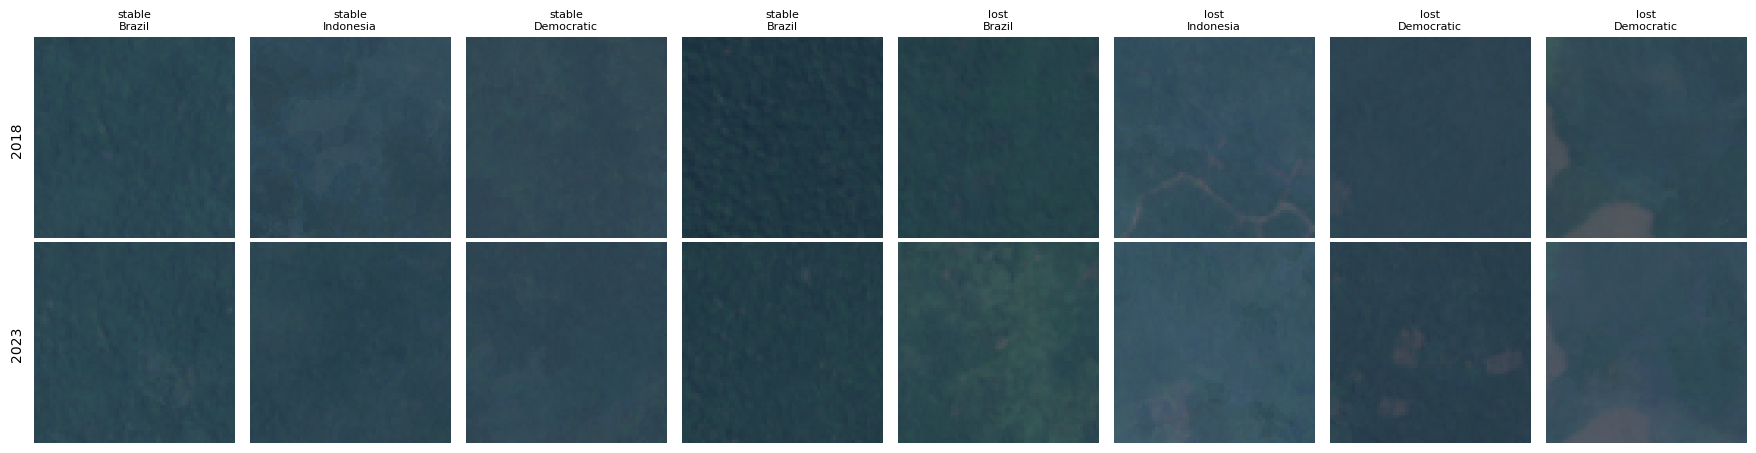

In [14]:
import matplotlib.pyplot as plt

def rgb(arr, offset):
    img = arr[[offset + 2, offset + 1, offset]].transpose(1, 2, 0).astype(float)  # B4, B3, B2
    return np.clip(img / 3000, 0, 1)

if "balanced_sample" not in globals():   # defined in section 5; repeated here in case section 5 was skipped
    def balanced_sample(df, n):
        parts = [g.sample(min(len(g), n), random_state=SEED) for _, g in df.groupby("label")]
        return pd.concat(parts) if parts else df.iloc[0:0]

sample = balanced_sample(index, 4)
assert len(sample) > 0, "no saved patches to show"
fig, axes = plt.subplots(2, len(sample), figsize=(2.2 * len(sample), 4.6), squeeze=False)
for col, row in enumerate(sample.itertuples()):
    arr = patches[row.patch_id]
    axes[0, col].imshow(rgb(arr, 0)); axes[0, col].set_title(f"{'lost' if row.label else 'stable'}\n{row.country[:10]}", fontsize=8)
    axes[1, col].imshow(rgb(arr, 6))
    for ax in axes[:, col]:
        ax.axis("off")
axes[0, 0].text(-8, 32, str(BEFORE_YEAR), rotation=90, va="center")
axes[1, 0].text(-8, 32, str(AFTER_YEAR), rotation=90, va="center")
plt.tight_layout()
plt.show()

## Sources and credits

- Hansen, M. C. et al. (2013). High-Resolution Global Maps of 21st-Century Forest Cover Change. *Science* 342, 850–853. Data: University of Maryland, CC BY 4.0.
- Contains modified Copernicus Sentinel data (2018, 2023).
- Pasquarella, V. J. et al. (2023). Cloud Score+ for Sentinel-2.
- FAO Global Administrative Unit Layers (GAUL) 2015.